# P1. 확률의 규칙: 넓이로 보는 확률과 조건부 확률

**목표**
- 확률을 "전체 넓이 1 인 땅에서 어떤 부분이 차지하는 넓이"로 읽는 눈을 만듭니다.
- 여사건, 덧셈 규칙, 곱셈 규칙, 조건부 확률, 독립, 전체 확률의 법칙을 그림·숫자·시뮬레이션으로 하나씩 확인합니다.

**이 노트북이 답하는 질문**: 확률 계산은 몇 가지 규칙만 알면 됩니다. 그 규칙들은 무엇이고, "조건부"는 무엇을 바꾸나요?

**같이 볼 강의·교재**

| 이 노트북 | Harvard Stat 110 강의 [1] | Blitzstein & Hwang 교재 [2] |
|---|---|---|
| 표본 공간, 확률의 정의 | Lecture 1 Probability and Counting, Lecture 2 Story Proofs, Axioms of Probability | 1장 Probability and Counting |
| 덧셈 규칙, 여사건 | Lecture 3 Birthday Problem, Properties of Probability | 1장 |
| 조건부 확률, 곱셈 규칙, 독립 | Lecture 4 Conditional Probability | 2장 Conditional Probability |
| 전체 확률의 법칙 | Lecture 5 Conditioning Continued, Law of Total Probability | 2장 "Bayes' rule and the law of total probability" 절 |

In [1]:
# ---- common start (study_build/stats/_common_p14.py 에서 복사; 고칠 땐 그 파일을 고치고 sync_common.py) ----
# 그림 도구입니다. 펼치지 않아도 됩니다. 팔레트: Okabe-Ito, 색의 뜻은 고정(STYLE §1-3).
import logging, math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle, FancyArrowPatch
from scipy import stats

COL = dict(prior="#56B4E9", likelihood="#E69F00", posterior="#0072B2", evidence="#374151",
           A="#0072B2", B="#E69F00", part="#56B4E9", g1="#0072B2", g2="#E69F00",
           sim="#D1D5DB", simedge="#9CA3AF", theory="#222222", null="#9CA3AF",
           highlight="#CC79A7", ok="#009E73", ink="#222222", muted="#6B7280",
           grid="#E5E7EB", none="#E5E7EB", shade="#F3F4F6")
RAMP = ["#C3CAD4", "#98A2B0", "#6B7280", "#3F4652", "#111827"]   # 순서 있는 값(옅음 → 진함)

def apply_theme():
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5, "mathtext.fontset": "dejavusans",
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white"})

def panel(ax, letter, title, **kw):
    """왼쪽 정렬 'A   제목' 형식의 패널 제목"""
    ax.set_title(f"{letter}   {title}" if letter else title, **kw)

def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    return ax.text(x, y, text, **kw)

def callout(ax, x, y, text, **kw):
    """핵심 메시지 한 줄: 자주색 굵은 글씨 + 흰 바탕"""
    kw.setdefault("fontsize", 10); kw.setdefault("color", COL["highlight"]); kw.setdefault("fontweight", "semibold")
    kw.setdefault("bbox", dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9))
    return ax.text(x, y, text, **kw)

def ygrid(ax):
    ax.yaxis.grid(True); ax.set_axisbelow(True)

def formula_strip(ax, parts, y=0.5, fontsize=17, gap=0.012):
    """수식을 조각(chip)으로 그린다. parts = [(mathtext, color 또는 None, 아래 이름표 또는 None), ...]
    색이 있는 조각은 옅은 배경 상자 + 같은 색 이름표. 그림의 같은 색과 짝을 이룬다."""
    ax.set_axis_off(); fig = ax.figure
    r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); items = []
    for tex, color, label in parts:                        # 조각과 이름표 중 넓은 쪽을 칸 폭으로
        t = ax.text(0, y, tex, fontsize=fontsize, va="center", ha="center",
                    color=color or COL["ink"], transform=ax.transAxes)
        bb = t.get_window_extent(renderer=r).transformed(inv)
        lw = 0.0
        if label:
            tl = ax.text(0, 0, label, fontsize=9.5, fontweight="semibold", transform=ax.transAxes)
            lw = tl.get_window_extent(renderer=r).transformed(inv).width; tl.remove()
        items.append((t, bb, color, label, max(bb.width, lw)))
    total = sum(w for *_, w in items) + gap * (len(items) - 1)
    x = (1 - total) / 2                                    # 가운데 정렬
    for t, bb, color, label, w in items:
        cx = x + w / 2; t.set_x(cx); x += w + gap
        if color:
            ax.add_patch(FancyBboxPatch((cx - bb.width / 2 - 0.006, bb.y0 - 0.04), bb.width + 0.012, bb.height + 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.02", transform=ax.transAxes,
                                        facecolor=color, alpha=0.13, edgecolor="none", zorder=0))
        if label:
            ax.text(cx, bb.y0 - 0.12, label, ha="center", va="top", fontsize=9.5,
                    color=color or COL["muted"], fontweight="semibold", transform=ax.transAxes)

def concept_map(nodes, edges, figsize=(11, 3.4), title=None, box=(0.13, 0.2), label_dy=0.05):
    """개념 지도. nodes = {키: (x, y, '글자', 색 또는 None)}, edges = [(키1, 키2, '화살표 글자' 또는 '')].
    좌표는 0~1. 색이 있는 상자는 그 색의 옅은 바탕."""
    fig, ax = plt.subplots(figsize=figsize); ax.set_axis_off(); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    w, h = box
    for k, (x, y, label, color) in nodes.items():
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.01,rounding_size=0.03",
                                    facecolor=(color or COL["shade"]), alpha=0.22 if color else 1.0,
                                    edgecolor=(color or "#9CA3AF"), lw=1.2))
        ax.text(x, y, label, ha="center", va="center", fontsize=9.5, color=COL["ink"])
    for a, b, label in edges:
        (x1, y1), (x2, y2) = nodes[a][:2], nodes[b][:2]
        ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=12, color="#6B7280",
                                     lw=1.1, shrinkA=38, shrinkB=38, connectionstyle="arc3,rad=0.0"))
        if label:
            vertical = abs(x2 - x1) < 0.03
            ax.text((x1 + x2) / 2 + (0.012 if vertical else 0), (y1 + y2) / 2 + (0 if vertical else label_dy), label,
                    ha="left" if vertical else "center", va="center" if vertical else "bottom", fontsize=8.5,
                    color=COL["muted"], bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
    if title:
        ax.text(0, 1.02, title, fontsize=11.5, fontweight="semibold", transform=ax.transAxes, va="bottom")
    return fig

apply_theme()
# ---- common end ----

def dice_grid(ax, cells, title=None, show_sum=True):
    """두 주사위 36칸. cells = [(마스크 함수, 바탕색, 테두리색), ...] 순서대로 겹쳐 칠한다."""
    for i in range(1, 7):
        for j in range(1, 7):
            face, edge, lw = "white", "#D1D5DB", 0.8
            for f, fc, ec in cells:
                if f(i, j):
                    if fc: face = fc
                    if ec: edge, lw = ec, 2.2
            ax.add_patch(FancyBboxPatch((j - 0.45, 6.55 - i - 0.45 + 0.0), 0.9, 0.9,
                                        boxstyle="round,pad=0,rounding_size=0.12",
                                        facecolor=face, edgecolor=edge, lw=lw, alpha=1.0))
            if show_sum:
                ax.text(j, 6.55 - i, f"{i},{j}", ha="center", va="center", fontsize=7.5, color=COL["muted"])
    ax.set_xlim(-0.2, 7.6); ax.set_ylim(0.0, 6.75); ax.set_aspect("equal"); ax.set_axis_off()
    for j in range(1, 7):
        ax.text(j, 6.2, str(j), ha="center", va="bottom", fontsize=9, color=COL["ink"])
    for i in range(1, 7):
        ax.text(0.45, 6.55 - i, str(i), ha="right", va="center", fontsize=9, color=COL["ink"])
    note(ax, 6.6, 6.2, "second\ndie", ha="left", va="bottom")
    note(ax, -0.05, 3.05, "first die", rotation=90, ha="center", va="center")
    if title:
        ax.set_title(title, pad=22)

def light(c, a=0.35):
    """색을 흰색과 섞어 옅게"""
    import matplotlib.colors as mc
    r, g, b = mc.to_rgb(c)
    return (1 - a + a * r, 1 - a + a * g, 1 - a + a * b)

def draw_concept_map():
    nodes = {"S": (0.075, 0.5, "sample space\nall outcomes", None),
             "E": (0.235, 0.5, "events\nsubsets", None),
             "C": (0.405, 0.84, "complement\nnot A", None),
             "U": (0.405, 0.5, "addition rule\nA or B", None),
             "I": (0.405, 0.16, "multiplication\nA and B", None),
             "K": (0.585, 0.16, "conditional\nP(A | B)", COL["A"]),
             "D": (0.585, 0.84, "independence", None),
             "L": (0.765, 0.16, "total probability\nsum over cases", COL["evidence"]),
             "Y": (0.925, 0.5, "Bayes\n(P6)", None)}
    edges = [("S", "E", ""), ("E", "C", ""), ("E", "U", ""), ("E", "I", ""), ("I", "K", ""),
             ("K", "D", "P(A|B) = P(A)?"), ("K", "L", ""), ("L", "Y", "")]
    return concept_map(nodes, edges, title="Concept map: from outcomes to conditional probability")

def draw_sample_space():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})
    dice_grid(ax[0], [(lambda i, j: i + j == 7, light(COL["A"], 0.45), COL["A"])])
    panel(ax[0], "A", "36 equally likely outcomes; A = 'sum is 7'", pad=4)
    sims = np.random.default_rng(1).integers(1, 7, size=(20000, 2))
    est = np.cumsum(sims.sum(1) == 7) / np.arange(1, len(sims) + 1)
    a = ax[1]
    a.plot(np.arange(1, len(sims) + 1), est, color=COL["A"], lw=1.2)
    a.axhline(6 / 36, color=COL["ink"], ls=(0, (4, 2)), lw=1.2)
    a.set_xscale("log"); a.set_ylim(0, 0.4); ygrid(a)
    a.set_xlabel("number of simulated rolls (log scale)"); a.set_ylabel("fraction of rolls with sum 7")
    note(a, 25000, 6 / 36 + 0.012, "6/36 = 0.167", ha="right", color=COL["ink"], fontsize=9.5)
    callout(a, 30, 0.34, "the running fraction settles on 6/36")
    panel(a, "B", "Simulation agrees with counting")
    fig.tight_layout()
    return fig, est[-1]

def draw_area():
    rng = np.random.default_rng(2); n = 4000
    pts = rng.random((n, 2))
    inA = (pts[:, 0] < 0.6) & (pts[:, 1] < 0.5)
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.6))
    a = ax[0]
    a.add_patch(Rectangle((0, 0), 1, 1, facecolor="white", edgecolor=COL["evidence"], lw=1.5))
    a.add_patch(Rectangle((0, 0), 0.6, 0.5, facecolor=light(COL["A"], 0.4), edgecolor=COL["A"], lw=1.8))
    a.text(0.3, 0.25, "A\narea 0.6 x 0.5\n= 0.30", ha="center", va="center", fontsize=10.5, color=COL["A"], fontweight="semibold")
    a.text(0.8, 0.8, "the whole space\narea = 1", ha="center", va="center", fontsize=10, color=COL["evidence"])
    a.set_xlim(-0.02, 1.02); a.set_ylim(-0.02, 1.02); a.set_aspect("equal"); a.set_axis_off()
    panel(a, "A", "Probability = share of the area")
    a = ax[1]
    a.scatter(pts[~inA, 0], pts[~inA, 1], s=3, color=COL["simedge"], linewidths=0)
    a.scatter(pts[inA, 0], pts[inA, 1], s=3, color=COL["A"], linewidths=0)
    a.add_patch(Rectangle((0, 0), 1, 1, facecolor="none", edgecolor=COL["evidence"], lw=1.5))
    a.set_xlim(-0.02, 1.02); a.set_ylim(-0.02, 1.02); a.set_aspect("equal"); a.set_axis_off()
    callout(a, 0.5, -0.07, f"{inA.sum()} of {n} random darts land in A  ->  {inA.mean():.3f}", ha="center", va="top")
    panel(a, "B", "Throw random darts and count")
    fig.tight_layout()
    return fig, inA.mean()

def draw_complement(p_single=1 / 6, nmax=12):
    n = np.arange(1, nmax + 1); exact = 1 - (1 - p_single) ** n
    rng = np.random.default_rng(3)
    sim = [(rng.integers(1, 7, size=(20000, k)) == 6).any(1).mean() for k in n]
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    ax.plot(n, exact, color=COL["ink"], lw=1.6, marker="o", ms=4, label="1 - (5/6)^n")
    ax.scatter(n, sim, s=60, facecolors="none", edgecolors=COL["A"], linewidths=1.4, zorder=3, label="simulation")
    ax.axhline(0.5, color=COL["muted"], lw=0.8, ls=":")
    ax.annotate("", xy=(4, exact[3]), xytext=(4, 0.12), arrowprops=dict(arrowstyle="->", color=COL["highlight"], lw=1.3))
    callout(ax, 4.2, 0.12, f"n = 4: {exact[3]:.3f}, just over 1/2", va="center")
    ax.set_xticks(n); ax.set_ylim(0, 1.02); ygrid(ax)
    ax.set_xlabel("number of rolls n"); ax.set_ylabel("P(at least one 6)")
    note(ax, nmax, 0.3, "line and dots: exact 1 - (5/6)^n", ha="right", color=COL["ink"])
    note(ax, nmax, 0.24, "open circles: 20,000 simulated rounds each", ha="right", color=COL["A"])
    ax.set_title("'At least one' is easiest through 'none at all'")
    fig.tight_layout()
    return fig, exact, np.array(sim)

def draw_addition():
    A = lambda i, j: i % 2 == 0
    B = lambda i, j: i + j >= 9
    fig = plt.figure(figsize=(11, 6.2))
    gs = fig.add_gridspec(2, 2, height_ratios=[0.9, 4], width_ratios=[1, 1.05], hspace=0.12)
    axf = fig.add_subplot(gs[0, :])
    formula_strip(axf, [(r"$P(A\cup B)$", COL["evidence"], "A or B"), (r"$=$", None, None),
                        (r"$P(A)$", COL["A"], "1st even"), (r"$+$", None, None),
                        (r"$P(B)$", COL["B"], "sum >= 9"), (r"$-$", None, None),
                        (r"$P(A\cap B)$", COL["evidence"], "in both: counted twice")])
    ax = fig.add_subplot(gs[1, 0])
    dice_grid(ax, [(A, light(COL["A"], 0.45), None), (B, None, COL["B"])])
    panel(ax, "A", "Blue fill = A, orange outline = B", pad=4)
    ax = fig.add_subplot(gs[1, 1]); ax.set_axis_off()
    nA = sum(A(i, j) for i in range(1, 7) for j in range(1, 7)); nB = sum(B(i, j) for i in range(1, 7) for j in range(1, 7))
    nAB = sum(A(i, j) and B(i, j) for i in range(1, 7) for j in range(1, 7))
    rows = [("A (blue cells)", COL["A"], nA), ("B (orange outline)", COL["B"], nB),
            ("A and B (blue cell, orange outline)", COL["evidence"], nAB)]
    for k, (lab, c, v) in enumerate(rows):
        yy = 0.86 - 0.2 * k
        ax.add_patch(FancyBboxPatch((0.02, yy - 0.07), 0.96, 0.14, boxstyle="round,pad=0,rounding_size=0.03",
                                    transform=ax.transAxes, facecolor=c, alpha=0.12, edgecolor="none"))
        ax.text(0.06, yy, lab, va="center", fontsize=10.5, color=COL["ink"], transform=ax.transAxes)
        ax.text(0.94, yy, f"{v} / 36", va="center", ha="right", fontsize=11.5, fontweight="semibold", transform=ax.transAxes)
    ax.text(0.06, 0.24, f"A or B = {nA} + {nB} - {nAB} = {nA + nB - nAB} cells", fontsize=11.5, fontweight="semibold",
            color=COL["evidence"], transform=ax.transAxes)
    callout(ax, 0.06, 0.1, "without '- A and B', the 6 cells in both count twice", transform=ax.transAxes)
    panel(ax, "B", "Count the cells")
    return fig, (nA, nB, nAB)

def draw_conditional():
    A = lambda i, j: i % 2 == 0
    B = lambda i, j: i + j >= 9
    fig = plt.figure(figsize=(11.5, 6.4))
    gs = fig.add_gridspec(2, 2, height_ratios=[0.9, 4], hspace=0.12)
    axf = fig.add_subplot(gs[0, :])
    formula_strip(axf, [(r"$P(A\mid B)$", COL["A"], "A, once we know B"), (r"$=$", None, None),
                        (r"$P(A\cap B)$", COL["evidence"], "A inside B"), (r"$\div$", None, None),
                        (r"$P(B)$", COL["B"], "the new whole")])
    ax = fig.add_subplot(gs[1, 0])
    dice_grid(ax, [(A, light(COL["A"], 0.45), None), (B, None, COL["B"])])
    panel(ax, "A", "Before: the whole 36 cells", pad=4)
    note(ax, 3.5, -0.05, "P(A) = 18/36 = 0.50", ha="center", va="top", color=COL["A"], fontsize=10)
    ax = fig.add_subplot(gs[1, 1])
    cellsB = [(i, j) for i in range(1, 7) for j in range(1, 7) if B(i, j)]
    for k, (i, j) in enumerate(cellsB):
        x, y = k % 5, 1 - k // 5
        both = A(i, j)
        ax.add_patch(FancyBboxPatch((x - 0.42, y - 0.42), 0.84, 0.84, boxstyle="round,pad=0,rounding_size=0.1",
                                    facecolor=light(COL["A"], 0.45) if both else "white", edgecolor=COL["B"], lw=2.0))
        ax.text(x, y, f"{i},{j}", ha="center", va="center", fontsize=10, color=COL["ink"])
    ax.set_xlim(-0.7, 4.7); ax.set_ylim(-1.3, 1.9); ax.set_aspect("equal"); ax.set_axis_off()
    callout(ax, 2, -0.95, f"P(A | B) = {sum(A(i, j) for i, j in cellsB)}/{len(cellsB)} = 0.60", ha="center")
    panel(ax, "B", "After learning B: only these 10 cells remain")
    return fig

def draw_tree(r=3, b=2):
    n = r + b
    fig, ax = plt.subplots(figsize=(10.5, 5.0)); ax.set_axis_off(); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    def node(x, y, txt, c, w=0.15, h=0.1):
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.02",
                                    facecolor=light(c, 0.35), edgecolor=c, lw=1.4))
        ax.text(x, y, txt, ha="center", va="center", fontsize=10)
    def edge(x1, y1, x2, y2, txt):
        ax.annotate("", xy=(x2 - 0.08, y2), xytext=(x1 + 0.08, y1), arrowprops=dict(arrowstyle="-|>", color="#6B7280", lw=1.1))
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.035, txt, ha="center", fontsize=10, color=COL["ink"],
                bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
    node(0.08, 0.5, f"urn\n{r} orange\n{b} blue", COL["evidence"], w=0.13, h=0.17)
    node(0.36, 0.76, "1st orange", COL["B"]); node(0.36, 0.24, "1st blue", COL["A"])
    edge(0.08, 0.5, 0.36, 0.76, f"{r}/{n}"); edge(0.08, 0.5, 0.36, 0.24, f"{b}/{n}")
    leaves = [(0.68, 0.9, "orange, orange", COL["B"], f"{r - 1}/{n - 1}", 0.76, r * (r - 1)),
              (0.68, 0.62, "orange, blue", COL["A"], f"{b}/{n - 1}", 0.76, r * b),
              (0.68, 0.38, "blue, orange", COL["B"], f"{r}/{n - 1}", 0.24, b * r),
              (0.68, 0.1, "blue, blue", COL["A"], f"{b - 1}/{n - 1}", 0.24, b * (b - 1))]
    for x, y, txt, c, pr, y0, num in leaves:
        node(x, y, txt, c); edge(0.36, y0, x, y, pr)
        ax.text(0.79, y, f"= {num}/{n * (n - 1)} = {num / (n * (n - 1)):.2f}", va="center", fontsize=10.5,
                fontweight="semibold" if txt == "orange, orange" else "normal", color=COL["ink"])
    callout(ax, 0.6, 0.995, f"P(orange, orange) = {r}/{n} x {r - 1}/{n - 1} = {r * (r - 1) / (n * (n - 1)):.2f}", va="top")
    note(ax, 0.08, 0.36, "draw two balls\nwithout putting back", ha="center", va="top")
    return fig, r * (r - 1) / (n * (n - 1))

def draw_independence():
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.8))
    a = ax[0]
    a.add_patch(Rectangle((0, 0), 1, 1, facecolor="white", edgecolor=COL["evidence"], lw=1.5))
    a.add_patch(Rectangle((0, 0), 0.5, 1, facecolor=light(COL["A"], 0.3), edgecolor="none"))
    a.add_patch(Rectangle((0, 0), 1, 0.4, facecolor=light(COL["B"], 0.35), edgecolor="none", alpha=0.85))
    a.add_patch(Rectangle((0, 0), 0.5, 0.4, facecolor=light(COL["evidence"], 0.3), edgecolor=COL["evidence"], lw=1.6))
    a.text(0.25, 0.72, "A: width 0.5", ha="center", color=COL["A"], fontweight="semibold")
    a.text(0.75, 0.2, "B: height 0.4", ha="center", color="#B7791F", fontweight="semibold")
    a.text(0.25, 0.2, "A and B\n0.5 x 0.4\n= 0.20", ha="center", va="center", fontsize=10)
    a.set_xlim(-0.02, 1.02); a.set_ylim(-0.02, 1.02); a.set_aspect("equal"); a.set_axis_off()
    callout(a, 0.5, -0.06, "independent: inside A, B still takes 40%", ha="center", va="top")
    panel(a, "A", "Independent: overlap = product")
    a = ax[1]
    a.add_patch(Rectangle((0, 0), 1, 1, facecolor="white", edgecolor=COL["evidence"], lw=1.5))
    a.add_patch(Rectangle((0, 0), 0.5, 1, facecolor=light(COL["A"], 0.3), edgecolor="none"))
    a.add_patch(Rectangle((0.5, 0.0), 0.5, 0.8, facecolor=light(COL["B"], 0.35), edgecolor="none", alpha=0.85))
    a.text(0.25, 0.5, "A\n0.5", ha="center", va="center", color=COL["A"], fontweight="semibold")
    a.text(0.75, 0.4, "B\n0.4", ha="center", va="center", color="#B7791F", fontweight="semibold")
    a.set_xlim(-0.02, 1.02); a.set_ylim(-0.02, 1.02); a.set_aspect("equal"); a.set_axis_off()
    callout(a, 0.5, -0.06, "mutually exclusive: knowing A means B did not happen", ha="center", va="top")
    panel(a, "B", "Mutually exclusive: no overlap")
    fig.tight_layout()
    return fig

def draw_total_probability(purity=0.6, p_alt_t=0.5, p_alt_n=0.01):
    total = purity * p_alt_t + (1 - purity) * p_alt_n
    fig = plt.figure(figsize=(11, 6.0))
    gs = fig.add_gridspec(2, 2, height_ratios=[0.95, 4], width_ratios=[1.25, 1], hspace=0.12, wspace=0.32)
    axf = fig.add_subplot(gs[0, :])
    formula_strip(axf, [(r"$P(\mathrm{alt})$", COL["evidence"], "all alt reads"), (r"$=$", None, None),
                        (r"$P(\mathrm{alt}\mid T)$", COL["likelihood"], "alt rate in tumour"), (r"$\times$", None, None),
                        (r"$P(T)$", COL["prior"], "share from tumour"), (r"$+$", None, None),
                        (r"$P(\mathrm{alt}\mid N)$", COL["likelihood"], "alt rate in normal"), (r"$\times$", None, None),
                        (r"$P(N)$", COL["prior"], "share from normal")], fontsize=15)
    a = fig.add_subplot(gs[1, 0])
    a.add_patch(Rectangle((0, 0), purity, 1, facecolor=light(COL["prior"], 0.25), edgecolor=COL["prior"], lw=1.4))
    a.add_patch(Rectangle((purity, 0), 1 - purity, 1, facecolor=light(COL["prior"], 0.12), edgecolor=COL["prior"], lw=1.4))
    a.add_patch(Rectangle((0, 0), purity, p_alt_t, facecolor=light(COL["likelihood"], 0.6), edgecolor=COL["likelihood"], lw=1.4))
    a.add_patch(Rectangle((purity, 0), 1 - purity, p_alt_n, facecolor=COL["likelihood"], edgecolor=COL["likelihood"], lw=1.4))
    a.text(purity / 2, 0.75, f"reads from tumour cells\nP(T) = {purity}", ha="center", va="center", fontsize=10)
    a.text(purity + (1 - purity) / 2, 0.75, f"from normal cells\nP(N) = {1 - purity:.1f}", ha="center", va="center", fontsize=10)
    a.text(purity / 2, p_alt_t / 2, f"alt reads\n{purity} x {p_alt_t} = {purity * p_alt_t:.2f}", ha="center", va="center", fontsize=10)
    a.annotate(f"errors: {1 - purity:.1f} x {p_alt_n} = {(1 - purity) * p_alt_n:.3f}", xy=(purity + 0.2, p_alt_n),
               xytext=(purity + 0.02, 0.28), fontsize=9.5, arrowprops=dict(arrowstyle="->", color=COL["muted"]))
    a.set_xlim(-0.02, 1.02); a.set_ylim(-0.02, 1.02); a.set_axis_off()
    panel(a, "A", "Split the reads by where they came from")
    a = fig.add_subplot(gs[1, 1])
    rng = np.random.default_rng(4); n = 200_000
    from_t = rng.random(n) < purity
    alt = np.where(from_t, rng.random(n) < p_alt_t, rng.random(n) < p_alt_n)
    vals = [purity * p_alt_t, (1 - purity) * p_alt_n, total]
    simv = [(alt & from_t).mean(), (alt & ~from_t).mean(), alt.mean()]
    labs = ["alt and tumour", "alt and normal", "all alt reads"]
    y = np.arange(3)[::-1]
    a.scatter(vals, y, s=90, color=COL["ink"], zorder=3, label="formula")
    a.scatter(simv, y, s=180, facecolors="none", edgecolors=COL["likelihood"], linewidths=1.6, zorder=3, label="simulation")
    for v, yy in zip(vals, y):
        a.text(v + 0.012, yy + 0.18, f"{v:.3f}", fontsize=10, color=COL["ink"])
    a.set_yticks(y, labs); a.set_xlim(-0.012, 0.42); a.xaxis.grid(True); a.set_axisbelow(True)
    a.set_xlabel("share of all reads")
    note(a, 0.41, -0.55, "dot = formula, ring = 200,000 simulated reads", ha="right")
    callout(a, 0.41, 1.5, f"VAF = {total:.3f}, not 0.5", ha="right", va="center")
    panel(a, "B", "Add the pieces")
    fig.subplots_adjust(left=0.04, right=0.98)
    return fig, total, alt.mean()

## 개념 지도

아래 상자를 왼쪽에서 오른쪽으로 따라가면 이 노트북의 순서입니다. 마지막 "Bayes" 상자는 P6 에서 다룹니다.

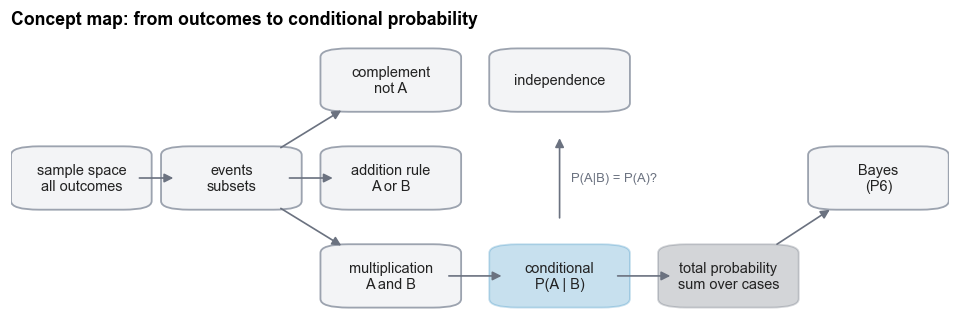

In [2]:
fig = draw_concept_map(); plt.show()

## 먼저 알아 둘 것: 기호 사전

확률 책을 읽을 때 막히는 곳은 대개 기호입니다. 이 노트북에서 쓰는 기호를 먼저 소리 내어 읽어 둡니다.

| 기호 | 소리 내어 읽기 | 뜻 |
|---|---|---|
| $\Omega$ | "오메가", 표본 공간 | 일어날 수 있는 모든 결과를 모은 것 |
| $A, B$ | 사건 A, 사건 B | 결과 몇 개를 묶은 것 (예: "합이 7") |
| $P(A)$ | "A 의 확률" | A 가 일어날 가능성, 0 과 1 사이 |
| $A^c$ | "A 여사건", "A 가 아닌 것" | A 에 들지 않는 결과 전부 |
| $A \cup B$ | "A 합집합 B", "A 또는 B" | A 나 B 중 하나라도 일어남 |
| $A \cap B$ | "A 교집합 B", "A 그리고 B" | A 와 B 가 함께 일어남 |
| $P(A \mid B)$ | "B 일 때 A 의 확률" | B 가 일어났다는 것을 알 때 A 의 확률 |
| $\sum_i$ | "i 에 대해 다 더한다" | 경우를 하나씩 바꿔 가며 더하기 |

## 1. 표본 공간과 사건

**한 줄 정의**: 표본 공간은 "일어날 수 있는 결과 전부의 목록"이고, 사건은 그 목록에서 몇 개를 고른 묶음입니다 [2].

**왜 필요한가**: 확률을 말하려면 "무엇 중에서 몇 개인가"가 정해져야 합니다. 전체가 무엇인지 흐리면 같은 질문에 다른 답이 나옵니다.

**숫자로 따라가기**: 주사위 두 개를 던지면 (첫째, 둘째) 쌍이 6 × 6 = 36 개 있고 모두 가능성이 같습니다.
"합이 7" 인 쌍은 (1,6), (2,5), (3,4), (4,3), (5,2), (6,1) 의 6 개입니다. 그래서 $P(\text{합이 7}) = 6/36 = 1/6$ 입니다.
이렇게 "가능성이 같은 결과들을 센다"는 정의는 결과가 모두 같은 가능성일 때만 쓸 수 있습니다(교재의 naive definition) [2].

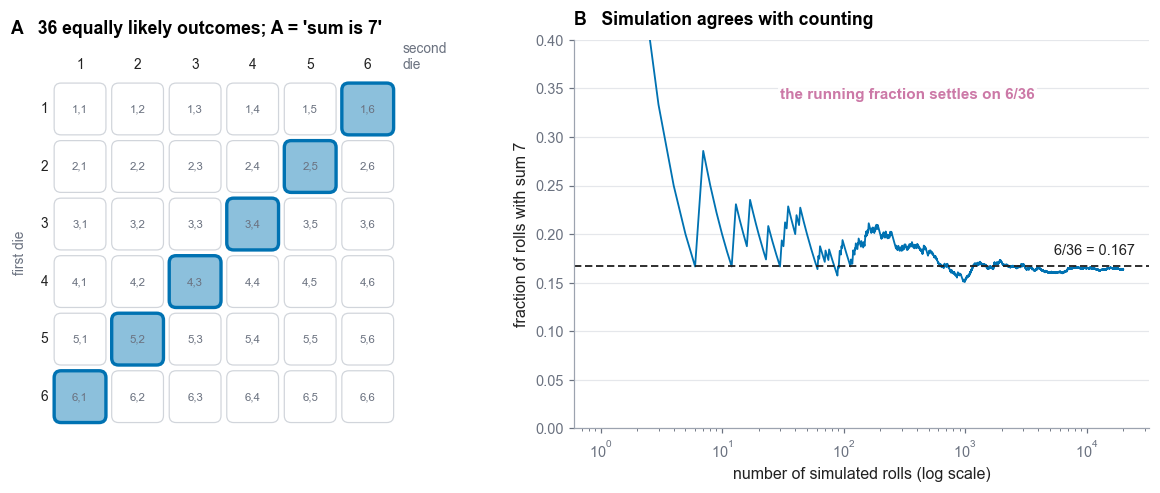

In [3]:
fig, est = draw_sample_space(); plt.show()
assert abs(est - 6 / 36) < 0.01

**그림에서 볼 것**
- A: 36 칸 중 파란 칸 6 개가 사건 A("합이 7")입니다. 칸 안 숫자는 (첫째, 둘째) 주사위 눈입니다.
- B: 주사위를 실제로 많이 던져 보면, 합이 7 인 비율(파란 선)이 처음엔 출렁이다가 점선 6/36 에 붙습니다.

**직접 바꿔 보기**: 아래 셀에서 사건을 "합이 10 이상"으로 바꿔 세어 보고, 시뮬레이션 값과 비교해 보세요.

In [4]:
rolls = np.random.default_rng(10).integers(1, 7, size=(100_000, 2))
count = sum(1 for i in range(1, 7) for j in range(1, 7) if i + j >= 10)
print("세기:", count, "/ 36 =", round(count / 36, 4), "  시뮬레이션:", round((rolls.sum(1) >= 10).mean(), 4))

세기: 6 / 36 = 0.1667   시뮬레이션: 0.1656


## 2. 확률 = 넓이

**한 줄 정의**: 확률은 "전체 넓이를 1 로 둔 땅에서 사건이 차지하는 넓이"로 생각할 수 있습니다.

**왜 필요한가**: 결과가 셀 수 없이 많을 때(키, 깊이 비, VAF 처럼 연속인 값)는 칸을 셀 수 없습니다. 넓이로 생각하면 셀 때와 같은 규칙이 그대로 이어집니다.
넓이로 생각하면 확률이 따르는 성질이 저절로 보입니다: 전체의 확률은 1, 빈 사건은 0, 겹치지 않는 사건들의 확률은 더한다.
확률을 이런 성질(공리, axiom)에서 출발해 정의하는 방법은 Stat 110 Lecture 2 "Axioms of Probability" 와 교재 1장 "Non-naive definition of probability" 절이 다룹니다 [1, 2]. 정확한 공리의 개수와 표현은 교재 본문에서 확인하세요(여기서는 목차만 확인했습니다).

**숫자로 따라가기**: 가로 0.6, 세로 0.5 인 사각형 A 의 넓이는 0.30 입니다. 땅 전체에 다트를 무작위로 던지면 약 30% 가 A 에 떨어져야 합니다.

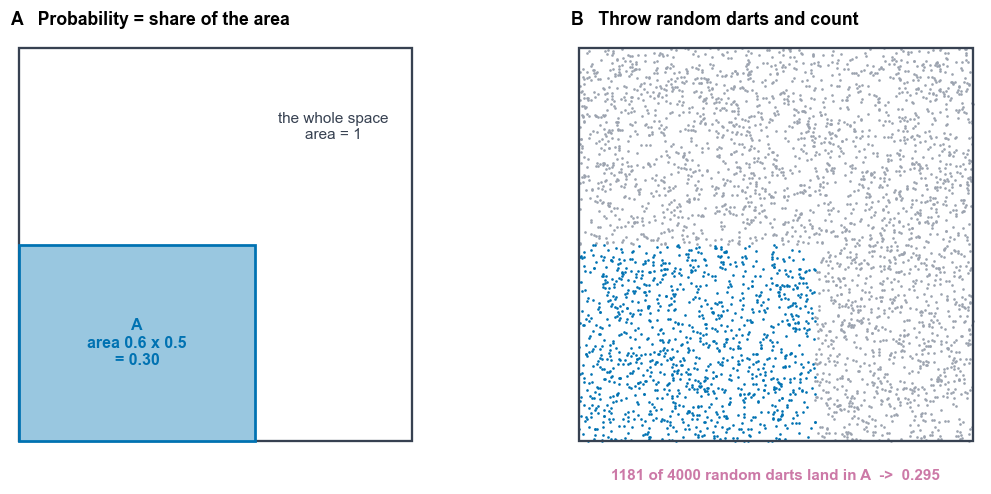

In [5]:
fig, frac = draw_area(); plt.show()
assert abs(frac - 0.30) < 0.03

**그림에서 볼 것**
- A: 바깥 사각형 전체가 넓이 1, 파란 사각형 A 가 넓이 0.30 입니다.
- B: 무작위 점 4,000 개 중 A 에 떨어진 비율이 0.30 근처입니다. 점을 늘리면 더 가까워집니다.

## 3. 여사건: "적어도 하나"는 "하나도 없음"을 빼서

**한 줄 정의**: A 가 일어나지 않는 경우 전부가 여사건 $A^c$ 이고, $P(A^c) = 1 - P(A)$ 입니다 [2].

**왜 필요한가**: "적어도 한 번" 같은 사건은 경우가 많아 직접 세기 어렵습니다. 반대인 "한 번도 없음"은 하나의 경우라 쉽습니다.

**숫자로 따라가기**: 주사위를 4 번 던질 때 6 이 한 번도 안 나올 확률은 $(5/6)^4 = 625/1296 = 0.482$ 입니다.
그래서 적어도 한 번 6 이 나올 확률은 $1 - 625/1296 = 671/1296 = 0.518$ 입니다.

**수식 풀어 읽기**

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $P(A^c)$ | "A 가 아닐 확률" | 적어도 한 번 6 이 나올 확률의 반대편 | 곡선 아래쪽 남은 부분 |
| $(5/6)^n$ | "6 분의 5 의 n 제곱" | n 번 모두 6 이 아님(매번 5/6, 서로 독립이라 곱함, 7 절) | 1 에서 곡선까지의 거리 |
| $1 - (5/6)^n$ | "1 빼기 ..." | 적어도 한 번 6 | 검은 곡선 |

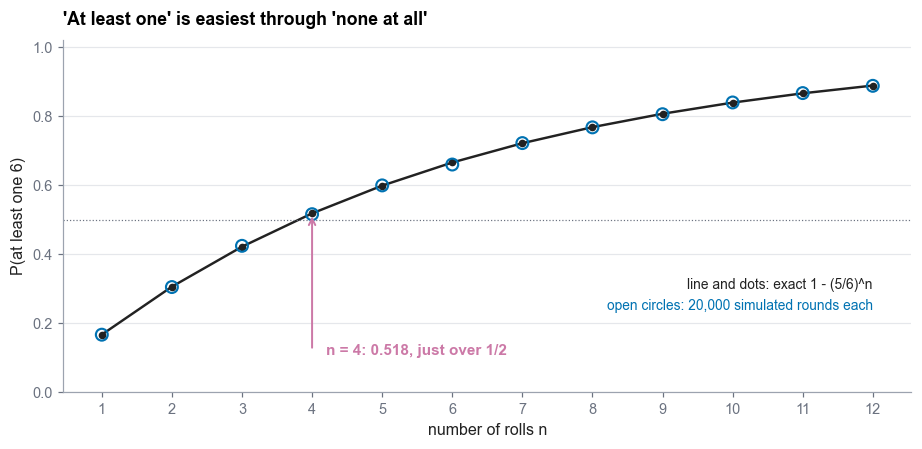

In [6]:
fig, exact, sim = draw_complement(); plt.show()
assert abs(exact[3] - 671 / 1296) < 1e-12 and np.allclose(sim, exact, atol=0.012)

**그림에서 볼 것**
- 검은 선과 점이 식 $1-(5/6)^n$, 파란 빈 원이 시뮬레이션(각 2 만 번)입니다. 두 개가 겹칩니다.
- 4 번째에서 처음으로 0.5(가는 점선)를 넘습니다(자주색 화살표).

> **시퀀싱 데이터에서는**: 진짜 VAF 가 0.05 인 변이를 깊이 30 으로 읽을 때, alt read 가 "적어도 한 개" 보일 확률은
> $1 - 0.95^{30} = 0.785$ 입니다. 같은 계산으로 "이 깊이에서 이 변이를 놓칠 확률"을 잴 수 있습니다.
> 실제 변이 호출기는 alt read 가 여러 개 필요하므로, "적어도 k 개"는 P3 의 이항 분포로 계산합니다.

## 4. 덧셈 규칙: "A 또는 B"

**한 줄 정의**: $P(A \cup B) = P(A) + P(B) - P(A \cap B)$ 입니다. 겹친 부분을 한 번 빼 줍니다 [2].

**왜 필요한가**: A 와 B 를 그냥 더하면 둘 다에 속한 결과를 두 번 셉니다.

**숫자로 따라가기**: A = "첫째 주사위가 짝수"(18 칸), B = "합이 9 이상"(10 칸), 둘 다인 칸은 6 개입니다.
그래서 $P(A \cup B) = (18 + 10 - 6)/36 = 22/36 = 0.611$ 입니다.

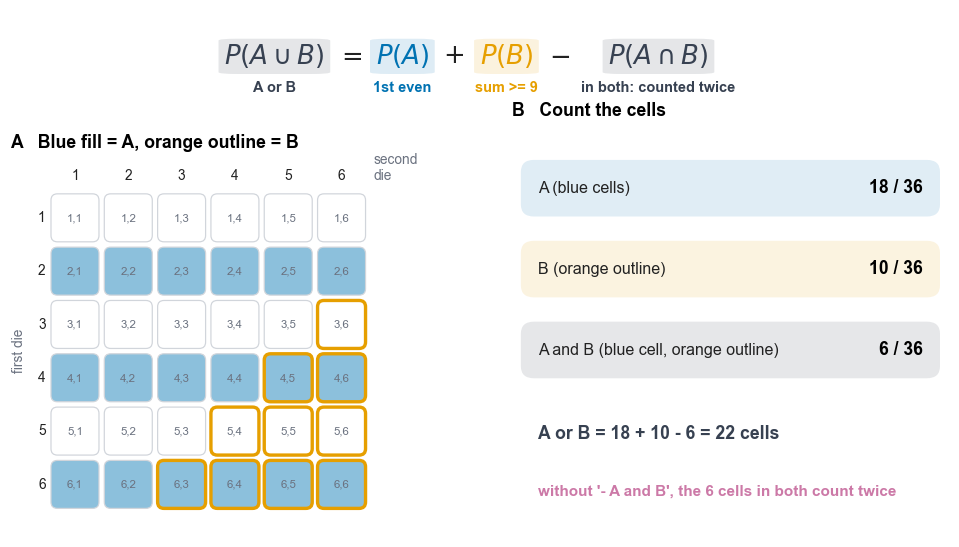

시뮬레이션 P(A 또는 B) = 0.6092   식 22/36 = 0.6111


In [7]:
fig, (nA, nB, nAB) = draw_addition(); plt.show()
sim = np.random.default_rng(11).integers(1, 7, size=(200_000, 2))
inA = sim[:, 0] % 2 == 0; inB = sim.sum(1) >= 9
assert (nA, nB, nAB) == (18, 10, 6)
assert abs((inA | inB).mean() - 22 / 36) < 0.005
print("시뮬레이션 P(A 또는 B) =", round((inA | inB).mean(), 4), "  식 22/36 =", round(22 / 36, 4))

**그림에서 볼 것**
- 위 수식 조각의 색이 아래 그림과 짝입니다. 파란 칸 = A, 주황 테두리 = B, 파란 칸이면서 주황 테두리 = 둘 다(진회색 조각).
- 둘 다인 6 칸은 파랑에도, 주황에도 들어 있습니다. 그래서 한 번 빼야 22 칸이 됩니다.

## 5. 조건부 확률: "B 안으로 확대해서 보기"

**한 줄 정의**: $P(A \mid B)$ 는 "B 가 일어났다는 것을 알 때 A 의 확률"이고, B 를 새 전체로 보고 그 안에서 A 가 차지하는 비율입니다 [2].

**왜 필요한가**: 정보가 생기면 가능한 결과가 줄어듭니다. 줄어든 세계에서 다시 비율을 재야 맞는 확률이 됩니다.

**숫자로 따라가기**: "합이 9 이상"(B)이라는 것을 알면 남는 칸은 10 개입니다. 그중 첫째가 짝수(A)인 칸은 6 개라서
$P(A \mid B) = 6/10 = 0.60$ 입니다. 아무것도 모를 때의 $P(A) = 18/36 = 0.50$ 보다 큽니다.

**수식 풀어 읽기**

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $P(A \mid B)$ | "B 일 때 A 의 확률" | B 가 일어난 경우만 놓고 그중 A 의 비율 | 오른쪽 10 칸 중 파란 칸 비율 |
| $P(A \cap B)$ | "A 그리고 B 의 확률" | 둘 다 일어날 확률, 6/36 | 파란 칸이면서 주황 테두리인 칸 |
| $P(B)$ | "B 의 확률" | 새 전체의 크기, 10/36 | 주황 테두리 칸 |

숫자를 넣으면 $(6/36) \div (10/36) = 6/10$ 입니다. 36 은 위아래에서 지워집니다. "새 전체로 다시 나눈다"는 뜻입니다.

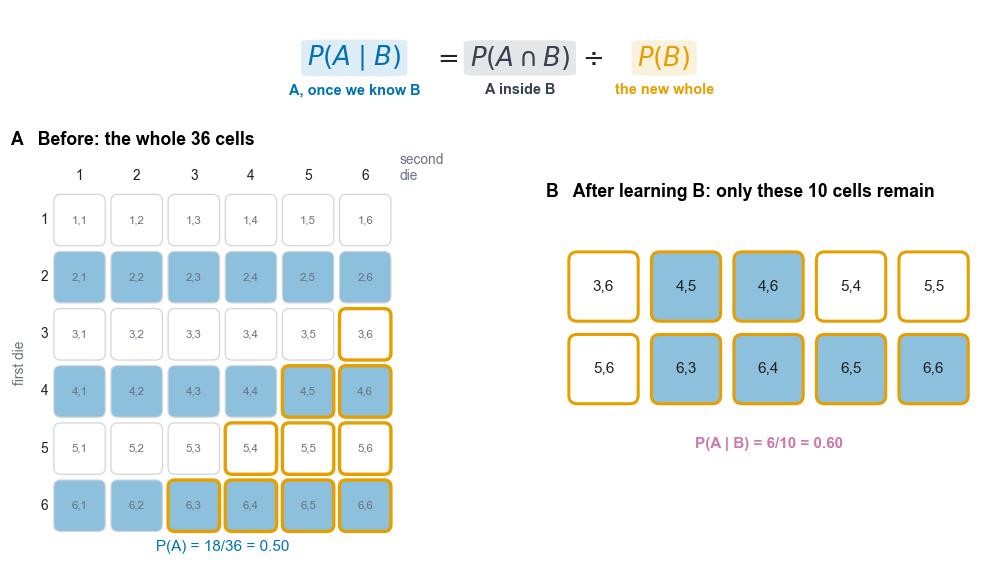

시뮬레이션 P(A | B) = 0.6008   식 6/10 = 0.6   거꾸로 P(B | A) = 0.3354 (식 6/18)


In [8]:
fig = draw_conditional(); plt.show()
cond = inA[inB].mean()                       # B 가 일어난 굴림만 남기고 그 안에서 A 비율
print("시뮬레이션 P(A | B) =", round(cond, 4), "  식 6/10 =", 0.6, "  거꾸로 P(B | A) =", round(inB[inA].mean(), 4), "(식 6/18)")
assert abs(cond - 0.6) < 0.01 and abs(inB[inA].mean() - 6 / 18) < 0.01

**그림에서 볼 것**
- A: 36 칸 전체. 파란 칸(A)은 절반입니다.
- B: B 를 알고 나면 주황 테두리 10 칸만 남습니다. 그 안에서 파란 칸(A 이기도 한 칸)이 6 칸이라 0.60 입니다.
- 순서를 바꾼 $P(B \mid A) = 6/18 = 0.33$ 은 $P(A \mid B)$ 와 다릅니다. **무엇을 아는가에 따라 나누는 전체가 바뀌기** 때문입니다.

> **시퀀싱 데이터에서는**: 세 가지 조건부 확률을 구분해야 합니다.
> - "진짜 변이가 있을 때 alt read 가 보일 확률": 그 변이의 VAF(purity·copy 수로 정해짐, 8 절)와 깊이가 정합니다.
> - "변이가 없을 때 alt read 가 보일 확률": 시퀀싱 오류율이 정합니다.
> - "alt read 가 보였을 때 진짜 변이일 확률": 우리가 알고 싶은 것은 대개 이것이고, 앞의 둘과 변이가 얼마나 흔한지를 함께 써서 P6 의 베이즈 정리로 계산합니다.

## 6. 곱셈 규칙과 나무 그림

**한 줄 정의**: $P(A \cap B) = P(A) \times P(B \mid A)$ 입니다. "먼저 A, 그다음 A 를 안 상태에서 B" 를 곱합니다 [2].

**왜 필요한가**: 여러 단계로 일어나는 일(두 번 뽑기, 조각이 나오고 그 조각이 alt 이기)은 단계마다 확률을 곱해 계산합니다. 5 절의 식을 양변에 $P(B)$ 를 곱해 바꾼 것과 같습니다.

**숫자로 따라가기**: 주황 공 3 개, 파란 공 2 개에서 두 개를 꺼내고 다시 넣지 않습니다.
첫째가 주황일 확률 3/5, 첫째가 주황일 때 둘째도 주황일 확률 2/4. 그래서 $P(\text{주황, 주황}) = 3/5 \times 2/4 = 6/20 = 0.30$ 입니다.

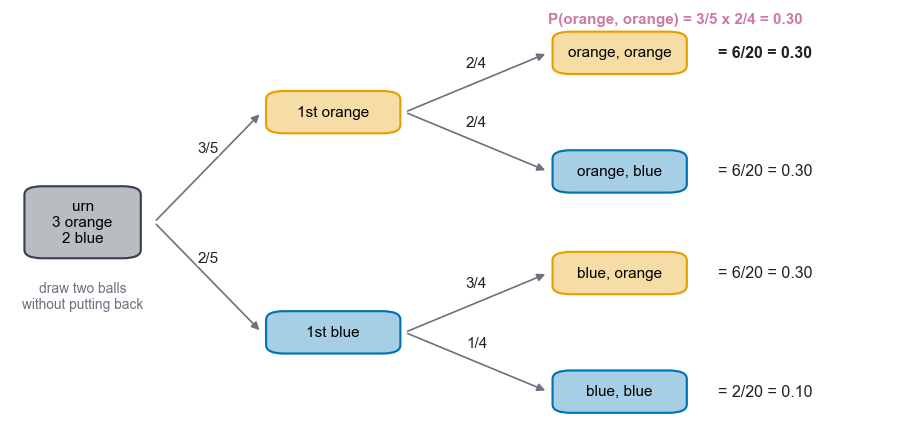

In [9]:
fig, p_rr = draw_tree(); plt.show()
draws = np.array([np.random.default_rng(12 + k).permutation([1, 1, 1, 0, 0])[:2] for k in range(20_000)])
assert abs(p_rr - 0.3) < 1e-12 and abs((draws.sum(1) == 2).mean() - 0.3) < 0.01

**그림에서 볼 것**
- 가지 위 숫자가 그 단계의 조건부 확률입니다. 둘째 단계의 숫자는 첫째에 무엇이 나왔는지에 따라 다릅니다(3/4 대 2/4).
- 오른쪽 끝 네 결과의 확률을 다 더하면 1 입니다(6 + 6 + 6 + 2 = 20 / 20).

## 7. 독립과 서로 배타: 헷갈리기 쉬운 두 낱말

**한 줄 정의**: 독립은 "B 를 알아도 A 의 확률이 그대로"($P(A \mid B) = P(A)$, 같은 말로 $P(A \cap B) = P(A)P(B)$)이고,
서로 배타는 "둘이 함께 일어날 수 없음"($A \cap B$ 가 비어 있음)입니다 [2].

**왜 필요한가**: 두 낱말은 거의 반대입니다. 확률이 둘 다 0 보다 큰 두 사건이 서로 배타이면, 하나를 알면 다른 하나가 안 일어났다는 것까지 알게 되므로 강하게 **의존**합니다($P(A \cap B) = 0 \ne P(A)P(B)$). 한쪽 확률이 0 이면 배타이면서 독립일 수도 있습니다.

**숫자로 따라가기**
- 독립: 첫째가 짝수(1/2)와 둘째가 짝수(1/2). 둘 다 짝수인 칸은 9 개라 $9/36 = 1/4 = 1/2 \times 1/2$ 입니다.
- 배타: 첫째가 짝수와 첫째가 홀수. 함께 일어나는 칸은 0 개입니다.

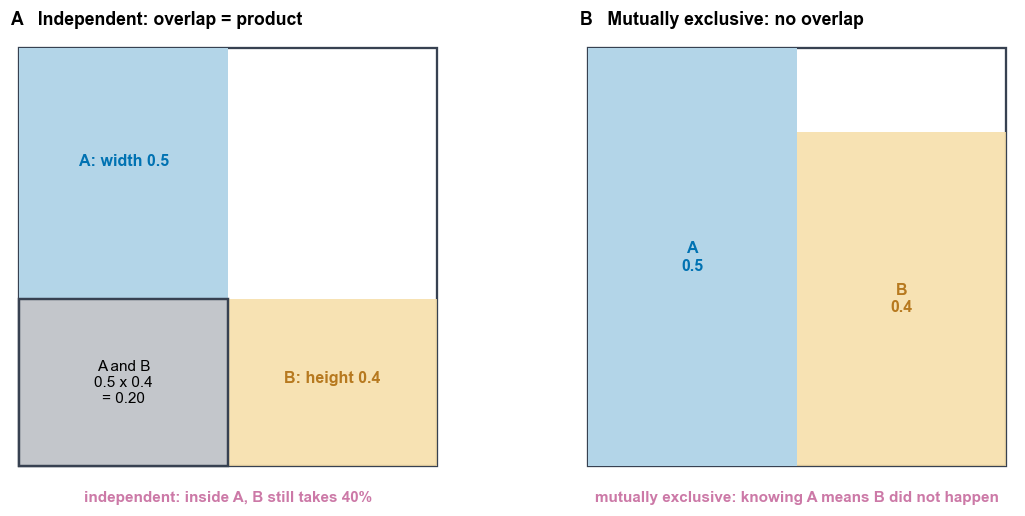

P(첫째 짝수 그리고 둘째 짝수) = 0.2497   P(A)P(B) = 0.25


In [10]:
fig = draw_independence(); plt.show()
second_even = sim[:, 1] % 2 == 0
print("P(첫째 짝수 그리고 둘째 짝수) =", round((inA & second_even).mean(), 4), "  P(A)P(B) =", 0.25)
assert abs((inA & second_even).mean() - 0.25) < 0.005 and abs(second_even[inA].mean() - 0.5) < 0.01

**그림에서 볼 것**
- A: A 는 왼쪽 세로 띠(폭 0.5), B 는 아래 가로 띠(높이 0.4)입니다. 겹친 칸(진회색 테두리)의 넓이가 정확히 곱 0.20 입니다.
  A 안에서도, A 밖에서도 B 가 차지하는 높이가 똑같이 40% 이므로 A 를 알아도 B 의 확률이 변하지 않습니다.
- B: 서로 배타면 겹친 곳이 없습니다. A 에 있으면 B 는 0% 입니다.

> **시퀀싱 데이터에서는**: VAF 를 이항 분포(P3)로 다룰 때는 "read 하나하나가 서로 독립으로 뽑힌다"고 가정합니다.
> PCR 중복 read 는 같은 DNA 분자의 복사본이라 이 가정을 깹니다. 그래서 중복을 표시하고 세지 않습니다(PURPLE B0 노트북 2 절).

## 8. 전체 확률의 법칙: 경우를 나눠 더하기

**한 줄 정의**: 전체를 겹치지 않는 경우 $A_1, A_2, \dots$ 로 나누면, $P(B) = \sum_i P(B \mid A_i)\,P(A_i)$ 입니다 [2].

**왜 필요한가**: B 가 일어나는 길이 여러 가지일 때, 길마다 따로 계산해서 더하면 됩니다. 이 식은 P6 베이즈 정리의 분모가 됩니다.

**숫자로 따라가기** (공부용으로 단순화한 예)
- 종양 시료의 DNA 조각 중 60% 가 종양 세포에서, 40% 가 정상 세포에서 왔다고 합니다.
  (종양과 정상 세포의 copy 수가 같을 때만 이 비율이 purity 와 같습니다. 다르면 PURPLE B1 노트북처럼 copy 수로 다시 계산합니다.)
- 종양 세포는 모두 그 자리 copy 수가 2(이배체)이고, 그중 한 copy 에만 변이가 있다고 합니다(클론 이형접합). 그러면 종양에서 온 read 의 절반(0.5)이 alt 입니다.
- 정상 세포에는 변이가 없고, 시퀀싱 오류로 **바로 그 alt 염기로** 잘못 읽히는 비율이 1%(0.01)라고 합니다.
- 종양에서 온 read 의 오류는 0 으로 두었습니다. (오류가 ref↔alt 양쪽으로 같은 비율로 일어난다면 종양 쪽 값은 0.5 그대로라 결과가 변하지 않습니다.)
- 그러면 $P(\text{alt}) = 0.5 \times 0.6 + 0.01 \times 0.4 = 0.300 + 0.004 = 0.304$ 입니다.

**수식 풀어 읽기**

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $P(T), P(N)$ | "종양에서 올 확률", "정상에서 올 확률" | 경우를 나누는 칸의 폭(합이 1) | 하늘색 두 칸의 폭 0.6, 0.4 |
| $P(\text{alt} \mid T)$ | "종양에서 왔을 때 alt 일 확률" | 그 칸 안에서 alt 의 높이 | 왼쪽 주황 높이 0.5 |
| $P(\text{alt} \mid N)$ | "정상에서 왔을 때 alt 일 확률" | 시퀀싱 오류율 | 오른쪽 아주 얇은 주황 띠 0.01 |
| $\sum$ | "다 더한다" | 칸마다 폭 × 높이 = 넓이를 더함 | 주황 넓이 전체 |

하늘색은 "경우의 크기", 주황은 "그 경우 안에서 alt 가 나올 확률"입니다. P6 에서 이 두 색이 각각 사전(prior)과 우도(likelihood)라는 이름으로 다시 나옵니다.

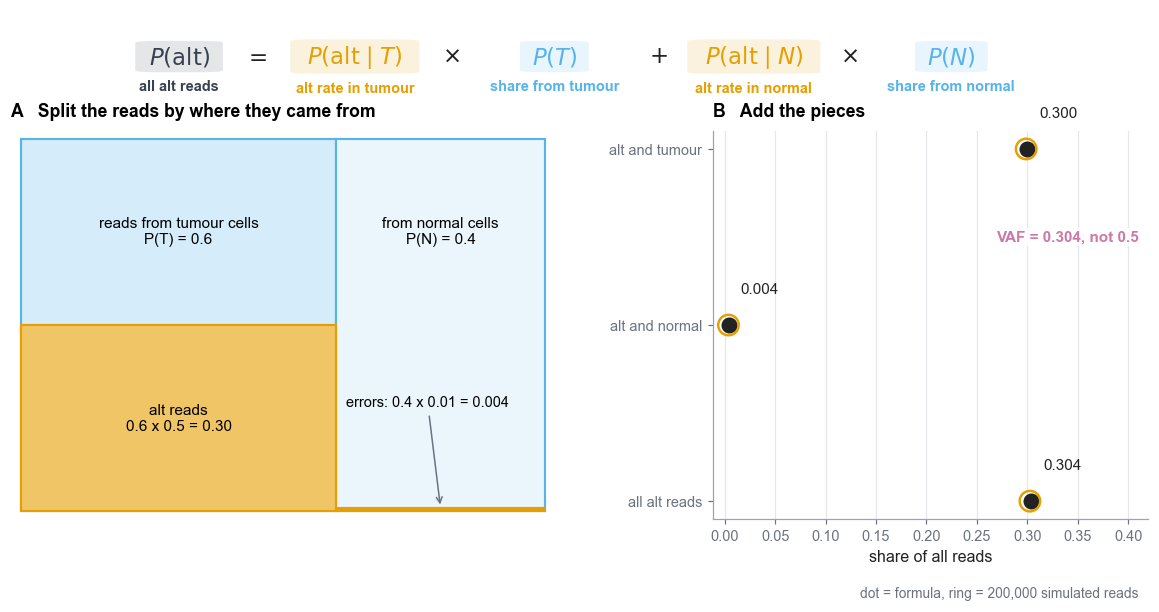

In [11]:
fig, total, sim_alt = draw_total_probability(); plt.show()
assert abs(total - 0.304) < 1e-12 and abs(sim_alt - 0.304) < 0.004

**그림에서 볼 것**
- A: 가로 폭이 "어디서 왔는가"(하늘색), 각 칸의 주황 높이가 "거기서 alt 일 확률"입니다. 주황 넓이를 더한 것이 전체 alt 비율입니다.
- B: 검은 점(식)과 주황 원(read 20 만 개 시뮬레이션)이 겹칩니다. 전체 alt 비율 0.304 는 0.5 가 아닙니다.

> **시퀀싱 데이터에서는**: 이것이 "purity 0.6 인 이배체 종양에서 클론 이형접합 변이의 VAF 는 약 0.3"인 이유입니다(PURPLE B1 노트북).
> 거꾸로 "이 alt read 하나는 종양에서 왔을까, 오류일까?"를 묻는 것이 베이즈 정리이고, P6 에서 이 그림을 그대로 이어서 씁니다.

**직접 바꿔 보기**: purity 를 0.2 로, 오류율을 0.005 로 바꿔 보세요. VAF 가 얼마나 작아지는지, 오류 몫의 비중이 얼마나 커지는지 보세요.

In [12]:
# fig, total, _ = draw_total_probability(purity=0.2, p_alt_n=0.005); plt.show(); print(total)

## 연습 문제

1. 주사위 두 개를 던질 때 "두 눈이 같다"(A)와 "합이 짝수"(B)는 독립일까요? 칸을 세어 확인하세요.
2. 주사위를 몇 번 던져야 "6 이 적어도 한 번"의 확률이 0.9 를 넘을까요?
3. 진짜 VAF 0.1 인 변이를 깊이 20 으로 읽을 때, alt read 가 하나도 없을 확률은?
4. 8 절에서 purity 0.6, 오류율 0.01 일 때, alt read 중 종양에서 온 것의 비율 $P(T \mid \text{alt})$ 은? (5 절의 식을 쓰세요. P6 에서 다시 봅니다.)

<details><summary>정답 보기</summary>

1. $P(A) = 6/36$, $P(B) = 18/36$, $P(A \cap B) = 6/36$ (같은 두 눈의 합은 늘 짝수). $P(A)P(B) = 3/36 \ne 6/36$ 이라 **독립이 아닙니다**. $P(B \mid A) = 1$ 입니다.
2. $1 - (5/6)^n > 0.9$ 를 풀면 $n > \log 0.1 / \log(5/6) = 12.6$, 즉 **13 번**입니다.
3. $0.9^{20} = 0.122$ 입니다.
4. $P(T \mid \text{alt}) = P(\text{alt} \cap T) / P(\text{alt}) = 0.300 / 0.304 = 0.987$ 입니다.

</details>

In [13]:
A1 = {(i, j) for i in range(1, 7) for j in range(1, 7) if i == j}
B1 = {(i, j) for i in range(1, 7) for j in range(1, 7) if (i + j) % 2 == 0}
assert len(A1 & B1) / 36 != (len(A1) / 36) * (len(B1) / 36)
assert min(n for n in range(1, 50) if 1 - (5 / 6) ** n > 0.9) == 13
assert abs(0.9 ** 20 - 0.1216) < 1e-3 and abs(0.300 / 0.304 - 0.987) < 1e-3

## 정리

- 확률은 "전체 1 인 땅에서 사건의 넓이"입니다. 가능성이 같은 결과라면 칸을 세어 나눕니다.
- 여사건: $P(A^c) = 1 - P(A)$. "적어도 하나"는 "하나도 없음"을 빼서 구합니다.
- 덧셈: $P(A \cup B) = P(A) + P(B) - P(A \cap B)$. 겹친 부분을 한 번 뺍니다.
- 조건부: $P(A \mid B) = P(A \cap B) / P(B)$. 아는 정보(B)를 새 전체로 삼아 다시 나눕니다. $P(A \mid B) \ne P(B \mid A)$.
- 곱셈: $P(A \cap B) = P(A) P(B \mid A)$. 나무 그림의 가지를 따라 곱합니다.
- 독립은 "알아도 안 바뀜", 배타는 "함께 못 일어남"이고 서로 다른 말입니다.
- 전체 확률: $P(B) = \sum_i P(B \mid A_i) P(A_i)$. 경우를 나눠 넓이를 더합니다. P6 베이즈 정리의 분모입니다.

## 출처

1. Harvard Statistics 110: Probability (Joe Blitzstein) 강의 영상, YouTube 재생목록. https://www.youtube.com/playlist?list=PL2SOU6wwxB0uwwH80KTQ6ht66KWxbzTIo
   — 머리말의 강의 번호와 제목(Lecture 1–5; Lecture 2 의 제목 "Story Proofs, Axioms of Probability"). 재생목록의 영상 제목으로 확인했고 영상 내용은 보지 않았습니다.
2. Blitzstein JK, Hwang J. *Introduction to Probability*, 2nd ed. Chapman & Hall/CRC, 2019. 목차: https://www.routledge.com/Introduction-to-Probability-Second-Edition/Blitzstein-Hwang/p/book/9781138369917 (저자 공개 PDF: http://probabilitybook.net)
   — **목차 기준(본문 미확인)**. 1장(Sample spaces, Naive definition of probability, Non-naive definition of probability)과 2장(Definition and intuition, Bayes' rule and the law of total probability, Independence of events)에 이 노트북의 주제가 있다는 것만 목차로 확인했습니다. 본문의 정의·정리·쪽수는 확인하지 못했습니다(공개 PDF 가 보기 전용이라 내려받지 못함). 본문에서 [2] 가 붙은 규칙은 모두 이 노트북의 시뮬레이션[3]으로 따로 확인합니다.
3. 이 노트북의 시뮬레이션 결과 — 그림 1B, 2B, 3, 4, 5, 6, 8B 의 시뮬레이션 값.
4. PURPLE 공부 노트북 B0(read 와 중복), B1(VAF 와 purity) — 같은 저장소 `03_genomics/purple-purity-ploidy/`.